# Priorización de casos de uso de datos: puntajes, ruido y decisiones de cartera

**Perfil:** Liderazgo de datos y gobierno  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Una matriz de priorización convierte opiniones (1 a 10) en un orden. Pero esas opiniones tienen **ruido**, **sesgo de halo** y **pesos arbitrarios**; y la decisión real es escoger un **portafolio con presupuesto**, no ordenar una lista. ¿Cuánto valor se pierde frente al óptimo? ¿Qué método resiste mejor el ruido? ¿Qué parte del ranking es robusta a los pesos?

## Recorrido

1. Un mundo sintético de 30 iniciativas con **valor y costo verdaderos** (oráculo) y calificaciones ruidosas con halo.
2. Cuatro métodos de priorización más el azar; **arrepentimiento** frente al portafolio óptimo (mochila exacta).
3. **Barrido de ruido** y **de halo**: cuándo los métodos dejan de ser mejores que sacar números al azar.
4. **Pesos inciertos:** índice de aceptabilidad de rangos y estabilidad del ordenamiento.
5. **Mochila** exacta (programación dinámica) frente al voraz por razón valor/costo.
6. **Frecuencia de selección** bajo ruido y el *núcleo robusto*.
7. **Dependencias entre iniciativas:** el costo de ignorarlas.
8. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats

## 2. El mundo: valor y costo verdaderos, calificaciones ruidosas

Cada iniciativa $i$ tiene un **valor** verdadero $V_i\sim\text{LogN}(\ln 3,\,0{,}9)$ (millones de USD en tres años) y un **costo** $C_i$ correlacionado con el valor (iniciativas más ambiciosas cuestan más). El presupuesto es el 35 % del costo total.

Los evaluadores no ven $V_i,C_i$: dan calificaciones enteras de 1 a 10 en cinco criterios, $s=\text{clip}\big(\text{round}(5{,}5+1{,}5\cdot(\cdot)),1,10\big)$ con

| criterio | señal | otros componentes |
|---|---|---|
| beneficio | $0{,}9\,z_V$ | ruido $e\sim N(0,\sigma^2)$ y **halo** $h_i\sim N(0,\sigma_h^2)$ |
| ajuste estratégico | $0{,}35\,z_V$ | independiente + ruido + halo |
| preparación de datos | $-0{,}3\,z_C$ | independiente + ruido + halo |
| esfuerzo | $0{,}9\,z_C$ | ruido |
| riesgo | $0{,}4\,z_C$ | independiente + ruido |

El **halo** $h_i$ es el entusiasmo compartido por una iniciativa (un patrocinador carismático): suma a los tres criterios *positivos* por igual y es independiente del valor verdadero.

In [2]:
N = 30
def mundo(rg, n=N):
    zv = rg.standard_normal(n); V = np.exp(np.log(3) + 0.9 * zv)
    zc = 0.6 * zv + 0.8 * rg.standard_normal(n); C = np.maximum(np.round(np.exp(np.log(1.2) + 0.6 * zc) / 0.05) * 0.05, 0.05)      # costos en multiplos de 0.05 M
    return V, C, (np.log(V) - np.log(V).mean()) / np.log(V).std(), (np.log(C) - np.log(C).mean()) / np.log(C).std()

def calificar(zv, zc, rg, sigma=0.5, halo=0.5):
    n = len(zv); u = rg.standard_normal((3, n)); h = halo * rg.standard_normal(n)
    e = lambda: sigma * rg.standard_normal(n)
    puntaje = lambda x: np.clip(np.round(5.5 + 1.5 * x), 1, 10)
    return pd.DataFrame({"beneficio": puntaje(0.9 * zv + e() + h), "ajuste": puntaje(0.35 * zv + 0.94 * u[0] + e() + h), "preparacion": puntaje(-0.3 * zc + 0.95 * u[1] + e() + h),
                         "esfuerzo": puntaje(0.9 * zc + e()), "riesgo": puntaje(0.4 * zc + 0.9 * u[2] + e())})

rg = np.random.default_rng(SEED); V0, C0, zv0, zc0 = mundo(rg); S0 = calificar(zv0, zc0, rg)
B0 = 0.35 * C0.sum()
mu = pd.DataFrame({"V_verdadero": V0, "C_verdadero": C0}).join(S0); mu["V/C"] = mu.V_verdadero / mu.C_verdadero
print(f"Valor total {V0.sum():.1f} M; costo total {C0.sum():.1f} M; presupuesto {B0:.1f} M")
print("Correlacion de cada calificacion con el valor/costo verdadero:")
print(pd.Series({"beneficio~V": np.corrcoef(S0.beneficio, np.log(V0))[0, 1], "ajuste~V": np.corrcoef(S0.ajuste, np.log(V0))[0, 1], "preparacion~C": np.corrcoef(S0.preparacion, np.log(C0))[0, 1],
                 "esfuerzo~C": np.corrcoef(S0.esfuerzo, np.log(C0))[0, 1], "riesgo~C": np.corrcoef(S0.riesgo, np.log(C0))[0, 1]}).round(2).to_string())
mu.head(6).round(2)

Valor total 116.2 M; costo total 51.0 M; presupuesto 17.8 M
Correlacion de cada calificacion con el valor/costo verdadero:
beneficio~V      0.7900
ajuste~V         0.0700
preparacion~C   -0.3400
esfuerzo~C       0.8800
riesgo~C         0.0800


,V_verdadero,C_verdadero,beneficio,ajuste,preparacion,esfuerzo,riesgo,V/C
0,1.4700,0.5000,4.0000,2.0000,8.0000,3.0000,6.0000,2.9400
1,3.7300,2.5000,6.0000,4.0000,3.0000,8.0000,5.0000,1.4900
2,0.5400,0.9000,3.0000,3.0000,4.0000,4.0000,5.0000,0.6000
3,10.5400,3.4000,7.0000,3.0000,1.0000,8.0000,9.0000,3.1000
4,5.3300,1.0000,8.0000,5.0000,6.0000,4.0000,6.0000,5.3300
5,2.3100,1.5000,5.0000,6.0000,8.0000,5.0000,9.0000,1.5400


## 3. Los métodos y la decisión

Cada método produce una **prioridad**; la cartera se arma **voraz**: en orden de prioridad se agrega cada iniciativa mientras el costo *estimado* (costo verdadero con error multiplicativo $\text{LogN}(0,0{,}25^2)$) quepa en el presupuesto. Se compara con el **óptimo** de la mochila con los valores y costos verdaderos (programación dinámica) y con una selección **al azar**.

- **Razón:** $\text{valor}/\text{esfuerzo}$ con $\text{valor}=0{,}5\,\text{ben}+0{,}3\,\text{ajuste}+0{,}2\,\text{prep}$ y $\text{esfuerzo}=0{,}6\,\text{esf}+0{,}4\,\text{riesgo}$.
- **Diferencia:** valor − esfuerzo (mismo puntaje).
- **TOPSIS:** cercanía al ideal (máx. beneficio, ajuste, preparación; mín. esfuerzo, riesgo) con los pesos 0,3/0,2/0,1/0,25/0,15.
- **Solo beneficio.**
- **Beneficio − esfuerzo:** usa únicamente los dos criterios que, por construcción, llevan la señal de $V$ y $C$ (en la práctica no se sabe de antemano cuáles criterios son informativos; aquí sirve para medir cuánto cuesta no saberlo).
- **Azar.**

*Hipótesis de partida (a contrastar con los datos):* las reglas que combinan valor y esfuerzo superan a mirar solo el beneficio.

*Arrepentimiento* $=1-\sum_{i\in\text{elegidos}}V_i\,/\,\sum_{i\in\text{óptimo}}V_i$.

In [3]:
def mochila_optima(V, C, B, unidad=0.05):
    c = np.ceil(C / unidad - 1e-9).astype(int); cap = int(np.floor(B / unidad + 1e-9)); n = len(V)         # costos multiplos de 'unidad': la mochila es exacta
    dp = np.zeros((n + 1, cap + 1)); 
    for i in range(1, n + 1):
        dp[i] = dp[i - 1]
        if c[i - 1] <= cap: dp[i, c[i - 1]:] = np.maximum(dp[i - 1, c[i - 1]:], dp[i - 1, :cap + 1 - c[i - 1]] + V[i - 1])
    sel = np.zeros(n, bool); j = cap
    for i in range(n, 0, -1):
        if dp[i, j] != dp[i - 1, j]: sel[i - 1] = True; j -= c[i - 1]
    return sel, dp[n, cap]

def val_esf(S): return 0.5 * S.beneficio + 0.3 * S.ajuste + 0.2 * S.preparacion, 0.6 * S.esfuerzo + 0.4 * S.riesgo
def p_razon(S): v, e = val_esf(S); return (v / e).values
def p_dif(S): v, e = val_esf(S); return (v - e).values
def p_beneficio(S): return S.beneficio.values + 1e-3 * S.ajuste.values
def p_topsis(S, w=(0.3, 0.2, 0.1, 0.25, 0.15)):
    cols = ["beneficio", "ajuste", "preparacion", "esfuerzo", "riesgo"]; X = S[cols].values.astype(float); X = X / np.sqrt((X ** 2).sum(axis=0)); X = X * np.array(w)
    ben = np.array([True, True, True, False, False]); ideal = np.where(ben, X.max(axis=0), X.min(axis=0)); anti = np.where(ben, X.min(axis=0), X.max(axis=0))
    dp_, dn = np.sqrt(((X - ideal) ** 2).sum(axis=1)), np.sqrt(((X - anti) ** 2).sum(axis=1)); return dn / (dp_ + dn)
def p_ben_esf(S): return (S.beneficio - S.esfuerzo).values + 1e-3 * S.ajuste.values            # solo los dos criterios informativos
METODOS = {"razon": p_razon, "diferencia": p_dif, "TOPSIS": p_topsis, "solo beneficio": p_beneficio, "beneficio-esfuerzo": p_ben_esf}

def cartera_voraz(prioridad, Cest, B):
    sel = np.zeros(len(prioridad), bool); gastado = 0.0
    for i in np.argsort(-prioridad):
        if gastado + Cest[i] <= B: sel[i] = True; gastado += Cest[i]
    return sel

def experimento(sigma, halo, R, seed, n=N):
    rg = np.random.default_rng(seed); filas = []
    for _ in range(R):
        V, C, zv, zc = mundo(rg, n); S = calificar(zv, zc, rg, sigma, halo); B = 0.35 * C.sum(); Cest = C * np.exp(0.25 * rg.standard_normal(n))
        _, vopt = mochila_optima(V, C, B); fila = {}
        for m, f in METODOS.items(): sel = cartera_voraz(f(S), Cest, B); fila[m] = 1 - V[sel].sum() / vopt
        sel = cartera_voraz(rg.random(n), Cest, B); fila["azar"] = 1 - V[sel].sum() / vopt
        sel_v = cartera_voraz(V / Cest, Cest, B); fila["oraculo voraz (V/C conocidos)"] = 1 - V[sel_v].sum() / vopt
        filas.append(fila)
    return pd.DataFrame(filas)

base = experimento(0.5, 0.5, 200, 1)
res0 = pd.DataFrame({"arrepentimiento_medio": base.mean(), "sd": base.std(), "P90": base.quantile(0.9), "mejor_que_azar_%": [(base[c] < base["azar"]).mean() for c in base.columns]}); res0.round(3)

,arrepentimiento_medio,sd,P90,mejor_que_azar_%
razon,0.2780,0.1400,0.4850,0.8200
diferencia,0.2750,0.1400,0.4770,0.8250
TOPSIS,0.2080,0.1250,0.3670,0.9050
solo beneficio,0.1750,0.1120,0.3210,0.9250
beneficio-esfuerzo,0.1970,0.1130,0.3320,0.9300
azar,0.4500,0.1350,0.6240,0.0000
oraculo voraz (V/C conocidos),0.0040,0.0550,0.0710,1.0000


In [4]:
print("Lectura (sigma=0.5, halo=0.5; 200 mundos):")
met = [m for m in METODOS]; rk = res0.loc[met, "arrepentimiento_medio"].sort_values()
print(f"  El azar pierde {base['azar'].mean():.0%} del valor optimo en promedio; el voraz que conociera V y C reales (con costo estimado ruidoso) pierde {base['oraculo voraz (V/C conocidos)'].mean():.1%}: el piso del esquema (voraz + error de costos) es casi cero.")
print("  Ranking de metodos por arrepentimiento: " + ", ".join(f"{m} {v:.0%}" for m, v in rk.items()) + ".")
print(f"  HIPOTESIS REFUTADA: 'razon' ({res0.loc['razon', 'arrepentimiento_medio']:.0%}) y 'diferencia' ({res0.loc['diferencia', 'arrepentimiento_medio']:.0%}) pierden MAS que mirar solo el beneficio ({res0.loc['solo beneficio', 'arrepentimiento_medio']:.0%}). Evidencia de la causa: 'diferencia' (5 criterios) y 'beneficio-esfuerzo' (solo los 2 informativos) usan la MISMA forma (valor − esfuerzo) y difieren en {res0.loc['diferencia', 'arrepentimiento_medio'] - res0.loc['beneficio-esfuerzo', 'arrepentimiento_medio']:.0%} de arrepentimiento solo por incluir criterios poco informativos (ajuste, preparacion y riesgo casi no correlacionan con V y C).")
print(f"  Usando solo los dos criterios informativos ('beneficio-esfuerzo') se pierde {res0.loc['beneficio-esfuerzo', 'arrepentimiento_medio']:.0%}: el valor de una matriz de priorizacion depende de que sus criterios y pesos reflejen la informacion que realmente tiene cada uno.")

Lectura (sigma=0.5, halo=0.5; 200 mundos):
  El azar pierde 45% del valor optimo en promedio; el voraz que conociera V y C reales (con costo estimado ruidoso) pierde 0.4%: el piso del esquema (voraz + error de costos) es casi cero.
  Ranking de metodos por arrepentimiento: solo beneficio 17%, beneficio-esfuerzo 20%, TOPSIS 21%, diferencia 27%, razon 28%.
  HIPOTESIS REFUTADA: 'razon' (28%) y 'diferencia' (27%) pierden MAS que mirar solo el beneficio (17%). Evidencia de la causa: 'diferencia' (5 criterios) y 'beneficio-esfuerzo' (solo los 2 informativos) usan la MISMA forma (valor − esfuerzo) y difieren en 8% de arrepentimiento solo por incluir criterios poco informativos (ajuste, preparacion y riesgo casi no correlacionan con V y C).
  Usando solo los dos criterios informativos ('beneficio-esfuerzo') se pierde 20%: el valor de una matriz de priorizacion depende de que sus criterios y pesos reflejen la informacion que realmente tiene cada uno.


## 4. ¿Cuánto ruido soportan los métodos?

Se barre la desviación del evaluador $\sigma$ de 0 a 2 (con halo 0,5) y luego el halo de 0 a 1,5 (con $\sigma=0{,}5$), 120 mundos por punto.

Arrepentimiento medio segun el ruido del evaluador:
        razon  diferencia  TOPSIS  solo beneficio  beneficio-esfuerzo   azar  oraculo voraz (V/C conocidos)
sigma                                                                                                      
0.0000 0.2440      0.2480  0.1700          0.1530              0.1320 0.4290                        -0.0060
0.5000 0.2640      0.2620  0.1970          0.1830              0.1980 0.4380                        -0.0070
1.0000 0.3040      0.3010  0.2640          0.2540              0.2780 0.4210                        -0.0020
1.5000 0.3230      0.3260  0.2990          0.2790              0.3050 0.4490                         0.0020
2.0000 0.3370      0.3330  0.3180          0.3000              0.3180 0.4470                        -0.0080

Arrepentimiento medio segun el halo:
        razon  diferencia  TOPSIS  solo beneficio  beneficio-esfuerzo   azar  oraculo voraz (V/C conocidos)
halo                                          

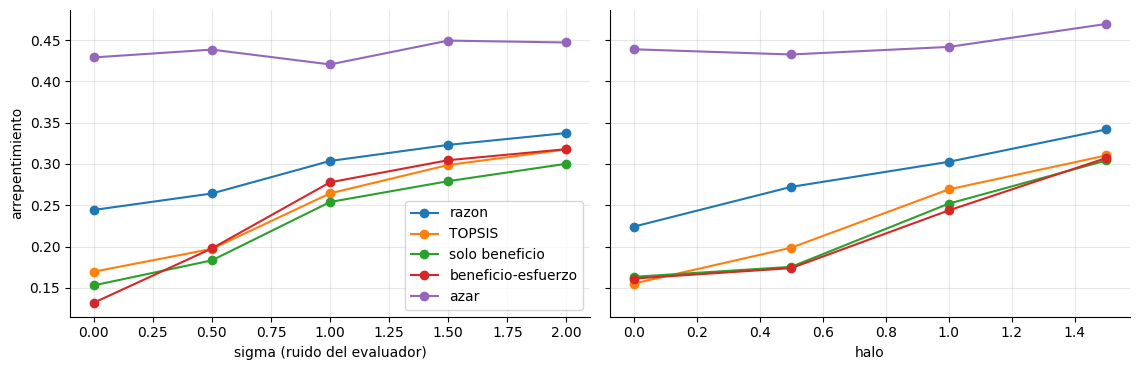

In [5]:
sig_res = {s: experimento(s, 0.5, 120, 10 + int(s * 10)).mean() for s in (0.0, 0.5, 1.0, 1.5, 2.0)}
sw = pd.DataFrame(sig_res).T; sw.index.name = "sigma"
halo_res = {h: experimento(0.5, h, 120, 50 + int(h * 10)).mean() for h in (0.0, 0.5, 1.0, 1.5)}
hw = pd.DataFrame(halo_res).T; hw.index.name = "halo"
print("Arrepentimiento medio segun el ruido del evaluador:"); print(sw.round(3).to_string()); print("\nArrepentimiento medio segun el halo:"); print(hw.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
for c in ["razon", "TOPSIS", "solo beneficio", "beneficio-esfuerzo", "azar"]: ax[0].plot(sw.index, sw[c], "o-", label=c); ax[1].plot(hw.index, hw[c], "o-", label=c)
ax[0].set_xlabel("sigma (ruido del evaluador)"); ax[0].set_ylabel("arrepentimiento"); ax[1].set_xlabel("halo"); ax[0].legend(); plt.tight_layout(); plt.show()

In [6]:
mejor = lambda d: d[list(METODOS)].idxmin(axis=1)
print("Lectura:")
print(f"  Con evaluadores sin ruido (sigma=0) la mejor regla ({mejor(sw).loc[0.0]}) pierde {sw.loc[0.0, list(METODOS)].min():.0%}; con sigma=2 la mejor ({mejor(sw).loc[2.0]}) pierde {sw.loc[2.0, list(METODOS)].min():.0%}. La ventaja de 'razon' sobre el azar baja de {sw.loc[0.0, 'azar'] - sw.loc[0.0, 'razon']:+.0%} a {sw.loc[2.0, 'azar'] - sw.loc[2.0, 'razon']:+.0%} de valor optimo.")
print(f"  El halo tambien erosiona: con halo=1.5 'razon' pierde {hw.loc[1.5, 'razon']:.0%} (frente a {hw.loc[0.0, 'razon']:.0%} sin halo): el entusiasmo compartido infla el 'valor' sin tocar el 'esfuerzo', y favorece las iniciativas queridas, no las valiosas.")
print(f"  Mejor metodo segun el ruido: {dict(mejor(sw))}; segun el halo: {dict(mejor(hw))}.")

Lectura:
  Con evaluadores sin ruido (sigma=0) la mejor regla (beneficio-esfuerzo) pierde 13%; con sigma=2 la mejor (solo beneficio) pierde 30%. La ventaja de 'razon' sobre el azar baja de +18% a +11% de valor optimo.
  El halo tambien erosiona: con halo=1.5 'razon' pierde 34% (frente a 22% sin halo): el entusiasmo compartido infla el 'valor' sin tocar el 'esfuerzo', y favorece las iniciativas queridas, no las valiosas.
  Mejor metodo segun el ruido: {0.0: 'beneficio-esfuerzo', 0.5: 'solo beneficio', 1.0: 'solo beneficio', 1.5: 'solo beneficio', 2.0: 'solo beneficio'}; segun el halo: {0.0: 'TOPSIS', 0.5: 'beneficio-esfuerzo', 1.0: 'beneficio-esfuerzo', 1.5: 'solo beneficio'}.


## 5. Pesos inciertos: ¿qué parte del ranking es robusta?

Los pesos son una decisión humana. Se extraen 2.000 conjuntos de pesos de una **Dirichlet** centrada en los pesos base (concentración 20) para el valor $(\text{ben},\text{ajuste},\text{prep})$ y el esfuerzo $(\text{esf},\text{riesgo})$, y se calcula el **índice de aceptabilidad de rangos**: la probabilidad de que cada iniciativa esté entre las 8 primeras por razón valor/esfuerzo. También se mide la correlación de rangos (Kendall $\tau$) entre el ranking base y el obtenido con los pesos alternos.

In [7]:
def ranking_razon(S, wv, we): 
    v = S.beneficio * wv[0] + S.ajuste * wv[1] + S.preparacion * wv[2]; e = S.esfuerzo * we[0] + S.riesgo * we[1]; return (v / e).values
rg = np.random.default_rng(3); base_p = ranking_razon(S0, (0.5, 0.3, 0.2), (0.6, 0.4)); TOP = 8
top_base = set(np.argsort(-base_p)[:TOP]); cnt = np.zeros(N); taus = []; sol = []
for _ in range(2000):
    wv = rg.dirichlet(20 * np.array([0.5, 0.3, 0.2])); we = rg.dirichlet(20 * np.array([0.6, 0.4])); p = ranking_razon(S0, wv, we)
    cnt[np.argsort(-p)[:TOP]] += 1; taus.append(stats.kendalltau(base_p, p)[0]); sol.append(len(top_base & set(np.argsort(-p)[:TOP])) / TOP)
aceptab = pd.Series(cnt / 2000, name="P(top-8)")
orden_b = np.argsort(-base_p)
tab = pd.DataFrame({"iniciativa": orden_b[:12], "rango_base": np.arange(1, 13), "P(top-8)": aceptab.iloc[orden_b[:12]].values, "V/C_verdadero": (V0 / C0)[orden_b[:12]]}).set_index("iniciativa"); tab.round(3)

,rango_base,P(top-8),V/C_verdadero
iniciativa,,,
12,1,1.0000,3.5400
11,2,1.0000,4.5410
29,3,1.0000,3.5120
4,4,0.9970,5.3290
14,5,0.9860,2.0400
17,6,0.7200,4.9140
24,7,0.7380,4.4550
22,8,0.7200,3.0430
21,9,0.4140,2.4080


In [8]:
print("Lectura:")
print(f"  Con pesos que varian ~±0.1 alrededor de los base, el tau de Kendall medio con el ranking base es {np.mean(taus):.2f} (min {np.min(taus):.2f}); en promedio {np.mean(sol):.0%} del top-8 base se mantiene.")
print(f"  {int((aceptab >= 0.95).sum())} iniciativas estan en el top-8 en el 95% o mas de los pesos (nucleo robusto); {int(((aceptab > 0.05) & (aceptab < 0.95)).sum())} entran o salen segun los pesos (frontera).")
print(f"  Ranking base: la iniciativa #{int(tab.index[7])} (octava) esta en el top-8 solo en {tab.iloc[7]['P(top-8)']:.0%} de los pesos: el corte es arbitrario cerca del borde.")

Lectura:
  Con pesos que varian ~±0.1 alrededor de los base, el tau de Kendall medio con el ranking base es 0.89 (min 0.68); en promedio 89% del top-8 base se mantiene.
  5 iniciativas estan en el top-8 en el 95% o mas de los pesos (nucleo robusto); 7 entran o salen segun los pesos (frontera).
  Ranking base: la iniciativa #22 (octava) esta en el top-8 solo en 72% de los pesos: el corte es arbitrario cerca del borde.


## 6. Mochila exacta frente a voraz por razón

Dados los valores y costos, el **voraz por razón $V/C$** es la heurística habitual. Se compara con el óptimo de la mochila 0-1 (programación dinámica) en 300 mundos y se muestra un contraejemplo clásico donde el voraz falla.

In [9]:
def voraz_razon(V, C, B):
    sel = np.zeros(len(V), bool); g = 0.0
    for i in np.argsort(-(V / C)):
        if g + C[i] <= B: sel[i] = True; g += C[i]
    return sel
rg = np.random.default_rng(21); brechas = []; viol_c = 0
for _ in range(300):
    V, C, _, _ = mundo(rg); B = 0.35 * C.sum(); so, vo = mochila_optima(V, C, B); sv = voraz_razon(V, C, B)
    brechas.append(1 - V[sv].sum() / V[so].sum()); viol_c += C[so].sum() > B + 1e-9
br = np.array(brechas)
# contraejemplo clasico: la razon V/C elige primero la iniciativa chica y el presupuesto ya no alcanza para la grande
Vc, Cc, Bc = np.array([1.1, 10.0]), np.array([1.0, 10.0]), 10.0
so_c, vo_c = mochila_optima(Vc, Cc, Bc, unidad=0.5); sv_c = voraz_razon(Vc, Cc, Bc)
print(f"Brecha del voraz frente al optimo en 300 mundos: media {br.mean():.2%}, P95 {np.percentile(br, 95):.2%}, max {br.max():.2%}; el voraz coincide con el optimo en {(br < 1e-9).mean():.0%} de los mundos")
print(f"Contraejemplo: items V={Vc.tolist()} C={Cc.tolist()} B={Bc}: voraz elige {sv_c.astype(int).tolist()} (valor {Vc[sv_c].sum():.1f}); optimo elige {so_c.astype(int).tolist()} (valor {vo_c:.1f})")

Brecha del voraz frente al optimo en 300 mundos: media 0.45%, P95 1.62%, max 3.98%; el voraz coincide con el optimo en 40% de los mundos
Contraejemplo: items V=[1.1, 10.0] C=[1.0, 10.0] B=10.0: voraz elige [1, 0] (valor 1.1); optimo elige [0, 1] (valor 10.0)


In [10]:
print("Lectura:")
print(f"  Con 30 iniciativas y un presupuesto del 35%, el voraz por razon queda a {br.mean():.1%} del optimo en promedio y alcanza el optimo exacto en {(br < 1e-9).mean():.0%} de los mundos: el resultado practico es bueno.")
print("  Pero hay contraejemplos donde falla: la razon ordena por 'valor por dolar' y no ve que una iniciativa grande pueda llenar el presupuesto con mejor valor total. La mochila exacta cuesta milisegundos: no hay razon para no usarla cuando se conocen V y C.")

Lectura:
  Con 30 iniciativas y un presupuesto del 35%, el voraz por razon queda a 0.4% del optimo en promedio y alcanza el optimo exacto en 40% de los mundos: el resultado practico es bueno.
  Pero hay contraejemplos donde falla: la razon ordena por 'valor por dolar' y no ve que una iniciativa grande pueda llenar el presupuesto con mejor valor total. La mochila exacta cuesta milisegundos: no hay razon para no usarla cuando se conocen V y C.


## 7. Frecuencia de selección bajo ruido: el núcleo robusto

Un mismo conjunto de iniciativas, evaluado por equipos distintos, daría calificaciones distintas. Se repite la calificación 500 veces (mismo $V,C$, nuevo ruido y halo con $\sigma=0{,}5$) y se calcula la **frecuencia con que cada iniciativa es seleccionada**. El **núcleo robusto** (frecuencia ≥ 75 %) se compara con el óptimo verdadero: ¿qué tan seguro es lo que todos eligen?

Nucleo robusto (>=75%): 9 iniciativas; descartadas con seguridad (<=25%): 9; ambiguas: 12
De las del nucleo, 89% estan en el optimo verdadero; de las descartadas con seguridad, 11% estan en el optimo
V/C verdadero medio: nucleo 4.00, ambiguas 2.52, descartadas 1.16


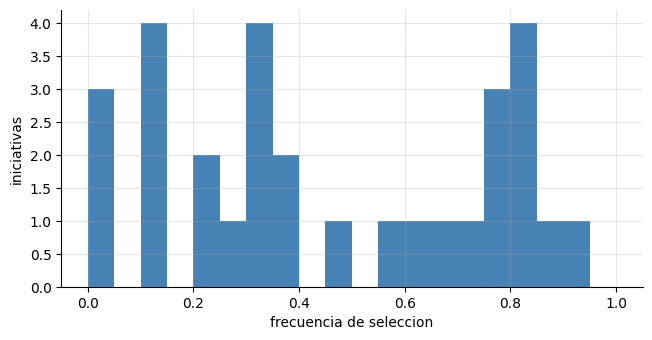

In [11]:
rg = np.random.default_rng(8); R = 500; frec = np.zeros(N); B = B0
so0, vo0 = mochila_optima(V0, C0, B)
for _ in range(R):
    S = calificar(zv0, zc0, rg, 0.5, 0.5); Cest = C0 * np.exp(0.25 * rg.standard_normal(N)); frec += cartera_voraz(p_razon(S), Cest, B)
frec /= R
UMB = 0.75; nucleo = frec >= UMB; fuera = frec <= 1 - UMB; ambig = ~nucleo & ~fuera
print(f"Nucleo robusto (>={UMB:.0%}): {nucleo.sum()} iniciativas; descartadas con seguridad (<={1 - UMB:.0%}): {fuera.sum()}; ambiguas: {ambig.sum()}")
print(f"De las del nucleo, {so0[nucleo].mean():.0%} estan en el optimo verdadero; de las descartadas con seguridad, {so0[fuera].mean():.0%} estan en el optimo")
print(f"V/C verdadero medio: nucleo {np.mean((V0 / C0)[nucleo]):.2f}, ambiguas {np.mean((V0 / C0)[ambig]):.2f}, descartadas {np.mean((V0 / C0)[fuera]):.2f}")
fig, ax = plt.subplots(figsize=(7.5, 3.6)); ax.hist(frec, bins=np.linspace(0, 1, 21), color="steelblue"); ax.set_xlabel("frecuencia de seleccion"); ax.set_ylabel("iniciativas"); plt.show()

In [12]:
print("Lectura:")
print(f"  {nucleo.sum() + fuera.sum()} de {N} iniciativas se deciden casi igual con cualquier evaluador (elegidas o descartadas con >={UMB:.0%} de las repeticiones), y {ambig.sum()} dependen del ruido. Conviene gastar el tiempo de discusion en estas ultimas, no en reordenar el nucleo.")
print(f"  Las del nucleo tienen una razon V/C verdadera mas alta ({np.mean((V0 / C0)[nucleo]):.2f}) que las ambiguas ({np.mean((V0 / C0)[ambig]):.2f}) y las descartadas ({np.mean((V0 / C0)[fuera]):.2f}): la frecuencia de seleccion es una medida de confianza informativa.")

Lectura:
  18 de 30 iniciativas se deciden casi igual con cualquier evaluador (elegidas o descartadas con >=75% de las repeticiones), y 12 dependen del ruido. Conviene gastar el tiempo de discusion en estas ultimas, no en reordenar el nucleo.
  Las del nucleo tienen una razon V/C verdadera mas alta (4.00) que las ambiguas (2.52) y las descartadas (1.16): la frecuencia de seleccion es una medida de confianza informativa.


## 8. Dependencias entre iniciativas

Algunas iniciativas **requieren** otra (la segmentación de clientes requiere el catálogo de datos). Si el ranking las ignora, la cartera puede incluir una iniciativa sin su requisito. Se generan 8 dependencias aleatorias $j\to i$ ($j$ requiere $i$), se mide la **fracción de carteras infactibles** del voraz que las ignora y se compara con la corrección por **agrupación**: una iniciativa con requisito se evalúa como un paquete (suma de valores y costos) y se elige al requisito antes.

In [13]:
def con_dependencias(prioridad, Cest, B, req):
    # req: dict j -> i. Se procesa en orden de prioridad; al elegir j se agrega su requisito (si falta) y se cobra su costo
    sel = np.zeros(len(prioridad), bool); g = 0.0
    for j in np.argsort(-prioridad):
        if sel[j]: continue
        extra = [j] + ([req[j]] if j in req and not sel[req[j]] else []); costo = sum(Cest[x] for x in extra)
        if g + costo <= B:
            for x in extra: sel[x] = True
            g += costo
    return sel

def infactible(sel, req): return any(sel[j] and not sel[i] for j, i in req.items())
rg = np.random.default_rng(31); R = 300; inf_n = inf_c = 0; perd = []; filas = []
for _ in range(R):
    V, C, zv, zc = mundo(rg); S = calificar(zv, zc, rg, 0.5, 0.5); B = 0.35 * C.sum(); Cest = C * np.exp(0.25 * rg.standard_normal(N))
    pares = rg.choice(N, (8, 2), replace=False); req = {int(j): int(i) for j, i in pares if int(j) != int(i)}
    p = p_razon(S); sn = cartera_voraz(p, Cest, B); sc = con_dependencias(p, Cest, B, req)
    inf_n += infactible(sn, req); inf_c += infactible(sc, req); filas.append({"valor_ignorando": V[sn].sum(), "valor_agrupando": V[sc].sum(), "valor_ignorando_si_factible": V[sn].sum() if not infactible(sn, req) else np.nan})
dep = pd.DataFrame(filas)
print(f"Carteras infactibles: ignorando dependencias {inf_n / R:.0%}; con agrupacion {inf_c / R:.0%}")
print(f"Valor medio de la cartera: ignorando {dep.valor_ignorando.mean():.1f} M (no factible en {inf_n / R:.0%} de los casos); agrupando {dep.valor_agrupando.mean():.1f} M (siempre factible); diferencia {dep.valor_agrupando.mean() / dep.valor_ignorando.mean() - 1:+.1%}")

Carteras infactibles: ignorando dependencias 91%; con agrupacion 0%
Valor medio de la cartera: ignorando 59.6 M (no factible en 91% de los casos); agrupando 57.5 M (siempre factible); diferencia -3.6%


In [14]:
print("Lectura:")
print(f"  Con 8 dependencias entre 30 iniciativas, {inf_n / R:.0%} de las carteras del ranking ingenuo son infactibles (incluyen una iniciativa sin su requisito).")
print(f"  La agrupacion garantiza factibilidad y cuesta {abs(dep.valor_agrupando.mean() / dep.valor_ignorando.mean() - 1):.1%} de valor frente a una cartera que ni siquiera se puede ejecutar: la 'ventaja' de ignorar las dependencias es ilusoria.")

Lectura:
  Con 8 dependencias entre 30 iniciativas, 91% de las carteras del ranking ingenuo son infactibles (incluyen una iniciativa sin su requisito).
  La agrupacion garantiza factibilidad y cuesta 3.6% de valor frente a una cartera que ni siquiera se puede ejecutar: la 'ventaja' de ignorar las dependencias es ilusoria.


## 9. Pruebas automáticas

In [15]:
# 9.1 la mochila exacta: factible, optima frente a fuerza bruta en instancias chicas, y domina a cualquier voraz
rg = np.random.default_rng(0); import itertools
for _ in range(40):
    n_ = 10; Vt = rg.random(n_) * 10; Ct = np.round(rg.random(n_) * 5 + 0.5, 1); Bt = Ct.sum() * 0.4
    so_, vo_ = mochila_optima(Vt, Ct, Bt, unidad=0.1)
    mejor_bf = max(Vt[list(c)].sum() for r_ in range(n_ + 1) for c in itertools.combinations(range(n_), r_) if Ct[list(c)].sum() <= Bt + 1e-9)
    assert abs(vo_ - mejor_bf) < 1e-9 and abs(Vt[so_].sum() - vo_) < 1e-9 and Ct[so_].sum() <= Bt + 1e-9
assert viol_c == 0 and (br >= -1e-12).all() and vo_c > Vc[sv_c].sum() + 1e-9                  # contraejemplo: el voraz pierde
# 9.2 TOPSIS acotado en [0,1], prioridades finitas; el azar pierde bastante
assert ((p_topsis(S0) >= 0) & (p_topsis(S0) <= 1)).all() and np.isfinite(p_razon(S0)).all()
assert 0.2 < base["azar"].mean() < 0.9 and base["oraculo voraz (V/C conocidos)"].mean() < 0.15
# 9.3 metodos con informacion de costo superan al azar; ignorar el costo es peor que usar la razon
assert all(base[m].mean() < base["azar"].mean() - 0.05 for m in METODOS)
# hipotesis inicial refutada: la razon NO supera a 'solo beneficio'; y los criterios poco informativos explican la diferencia (misma forma, 5 criterios vs 2)
assert base["solo beneficio"].mean() < base["razon"].mean() and base["beneficio-esfuerzo"].mean() < base["diferencia"].mean() - 0.03
# 9.4 el ruido erosiona: el arrepentimiento de la razon crece con sigma; sin ruido es mucho mejor que el azar
assert sw["razon"].is_monotonic_increasing and sw.loc[0.0, "razon"] < sw.loc[0.0, "azar"] - 0.1 and sw.loc[2.0, "azar"] - sw.loc[2.0, "razon"] < sw.loc[0.0, "azar"] - sw.loc[0.0, "razon"]
# 9.5 el halo erosiona
assert hw.loc[1.5, "razon"] > hw.loc[0.0, "razon"]
# 9.6 pesos inciertos
assert np.mean(taus) > 0.7 and 0 < ((aceptab > 0.05) & (aceptab < 0.95)).sum() < N and aceptab.max() <= 1
# 9.7 nucleo robusto: mejor razon V/C que el resto
assert nucleo.sum() >= 1 and np.mean((V0 / C0)[nucleo]) > np.mean((V0 / C0)[fuera])
# 9.8 dependencias: la agrupacion es siempre factible y el ranking ingenuo no
assert inf_c == 0 and inf_n / R > 0.2
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Ruido y halo | Las calificaciones ruidosas y con halo acercan el resultado al azar | Calibrar evaluadores y separar el entusiasmo del valor |
| Criterios | Añadir criterios poco informativos empeora la priorización: con la misma forma valor − esfuerzo, usar 5 criterios en lugar de los 2 informativos cuesta ~8 puntos de arrepentimiento; en este mundo 'solo beneficio' fue la mejor regla | Ponderar por la información real de cada criterio y validar contra resultados pasados |
| Pesos | El ordenamiento cambia con los pesos, sobre todo cerca del corte | Reportar aceptabilidad de rangos, no un solo orden |
| Mochila | El voraz es bueno en promedio pero falla en casos concretos; la mochila exacta es barata | Resolver la cartera con optimización cuando se tienen costos |
| Robustez | La frecuencia de selección separa un núcleo seguro de las decisiones ambiguas | Dedicar la discusión a las ambiguas |
| Dependencias | Ignorarlas produce carteras que no se pueden ejecutar | Agrupar las iniciativas con sus requisitos |

**Límites que no deben ocultarse**

- El valor y el costo verdaderos son una ficción del simulador; en la práctica nunca se observan, solo estimaciones con sus propios sesgos.
- El modelo de evaluadores es sencillo (ruido gaussiano y halo común); los sesgos reales (anclaje, incentivos del patrocinador) son más complejos.
- El valor se suma de forma aditiva; las iniciativas reales tienen sinergias y cuellos de botella de capacidad que la mochila no recoge.
- Los porcentajes de arrepentimiento dependen del presupuesto (35 %), del tamaño de cartera (30) y de las distribuciones elegidas.